# Directed Stochastic Block Model (DiSBM) dataset

This notebook contains the code used to analyze and plot the DiSBM dataset used in the experiments of the paper. 

In [1]:
%load_ext autoreload
%autoreload 2
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import numpy as np
from sklearn.manifold import Isomap
from finsler_embedding.experiments.disbm import *
from finsler_embedding.experiments.learning import interpolate_V
from finsler_embedding.core.inputs import from_graph
from finsler_embedding.utils import get_bounds, get_grid_pts
from finsler_embedding.experiments.palette import INK, SPEED

cmap = SPEED  # community index along the cycle

In [2]:
# Hyperparameters for the DiSBM dataset
N, K = 1000, 15
m = 2
eps_scale = .10

r = 0.1
p = 0.4
q = 1 - p - r

torch.manual_seed(0)
edges, edge_weights, community_labels, A = graph_info(p,q,r,K,N)

In [3]:
epsilon = 1
results = from_graph(A, epsilon, n_components=m)
W = results.kernel
X_low = results.coordinates

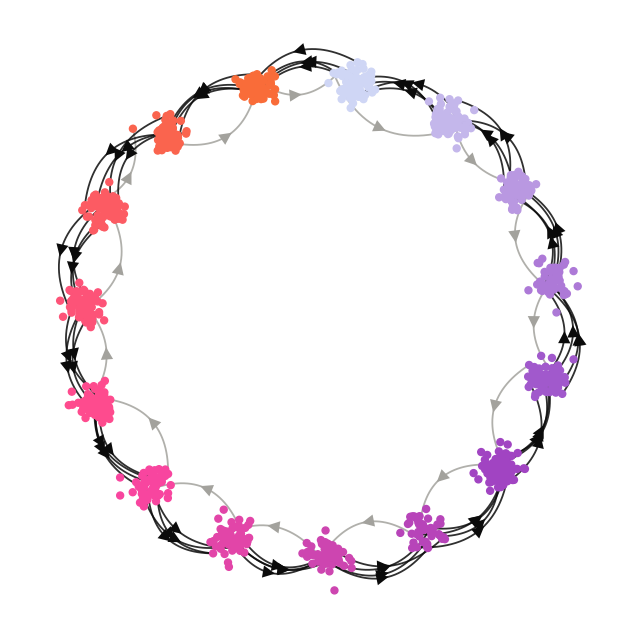

In [4]:
# Plotting a DiSBM graph (for illustration purposes only, not used in the experiments)
n_forward, n_backward = (4, 1) if p > q else (1, 4)
labels_np = community_labels.numpy()
mu = torch.stack([X_low[community_labels == k].mean(0) for k in range(K)]).numpy()
angles = np.arctan2(*(mu - mu.mean(0)).T[::-1])
orientation = np.sign(np.angle(np.exp(1j * (np.roll(angles, -1) - angles))).mean())  # +1: k -> k+1 counterclockwise
theta = angles[0] + orientation * 2 * np.pi * np.arange(K) / K
centers = np.stack([np.cos(theta), np.sin(theta)], axis=1)
rng = np.random.default_rng(0)
points = centers[labels_np] + 0.04 * rng.standard_normal((N, 2))

source, target = (t.numpy() for t in A.nonzero(as_tuple=True))
forward = labels_np[target] == (labels_np[source] + 1) % K
backward = labels_np[target] == (labels_np[source] - 1) % K
shown = []
for k in range(K):
    from_k = labels_np[source] == k
    shown += list(rng.choice(np.flatnonzero(from_k & forward), size=n_forward, replace=False))
    shown += list(rng.choice(np.flatnonzero(from_k & backward), size=n_backward, replace=False))

def arc_points(p0, p1, rad, n=30):
    d = p1 - p0
    control = (p0 + p1) / 2 + rad * np.array([d[1], -d[0]])
    t = np.linspace(0, 1, n)[:, None]
    return (1 - t) ** 2 * p0 + 2 * (1 - t) * t * control + t**2 * p1


fig, ax = plt.subplots(figsize=(8, 8))
for e in shown:
    color = "#a3a29d" if forward[e] else INK
    curve = arc_points(points[source[e]], points[target[e]], rad=0.45)
    ax.plot(curve[:, 0], curve[:, 1], color=color, linewidth=1.3, alpha=0.85, zorder=1, solid_capstyle="round")
    # Small arrowhead at the middle of the edge, pointing to its target
    mid = len(curve) // 2
    ax.annotate("", xy=curve[mid + 1], xytext=curve[mid - 1], zorder=1,
                arrowprops=dict(arrowstyle="-|>,head_length=0.8,head_width=0.4", color=color, linewidth=0,
                                shrinkA=0, shrinkB=0, mutation_scale=11))
ax.scatter(points[:, 0], points[:, 1], c=labels_np, cmap=cmap, s=25, zorder=2)
ax.set_aspect("equal")
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.axis("off")
fig.savefig("disbm_graph.pdf", bbox_inches="tight", pad_inches=0.)
plt.show()

## Comparisons of approaches

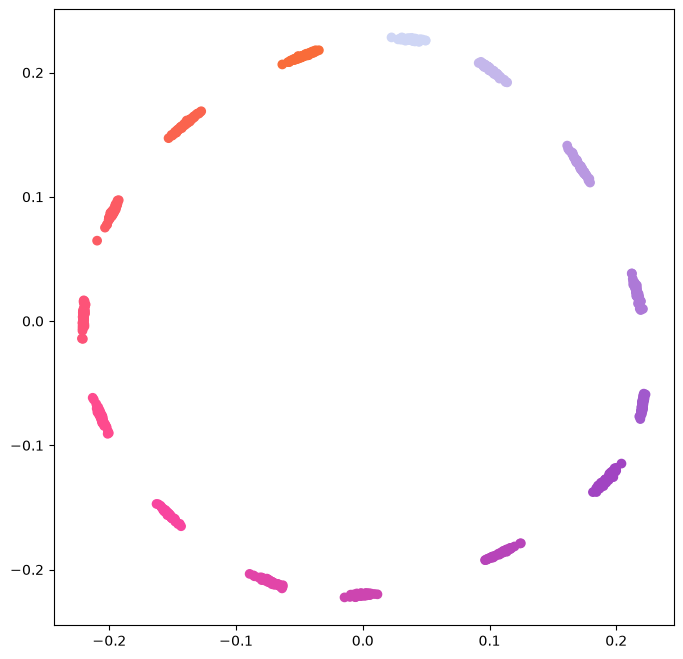

In [5]:
plt.figure(figsize=(8, 8))
plt.scatter(X_low[:,0].cpu().numpy(), X_low[:,1].cpu().numpy(), c=community_labels.cpu().numpy(), cmap=cmap)

In [6]:
V = results.drift
V_normed = V / (results.drift_norm_squared.sqrt() + 1e-12).unsqueeze(1)
unit_V = V / (V.norm(dim=1, keepdim=True) + 1e-12)

In [7]:
# Sort by x coords for display
idx = torch.argsort(X_low[:, 0])
X_low_plt = X_low[idx].clone()
V_plt = V[idx].clone()
unit_V_plt = unit_V[idx].clone()
community_labels_plt = community_labels[idx].clone()

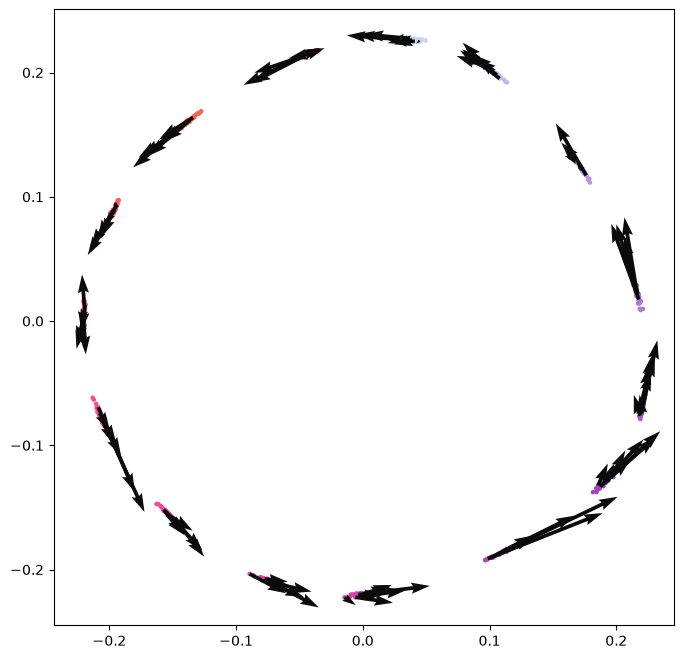

In [8]:
plt.figure(figsize=(8, 8))
cbar = plt.scatter(
    X_low_plt[:, 0], X_low_plt[:, 1], c=community_labels_plt, cmap=cmap,s=5
)
skip=10
plt.quiver(
    X_low_plt[::skip, 0],
    X_low_plt[::skip, 1],
    # unit_V_plt[::skip, 0],
    # unit_V_plt[::skip, 1],
    V_plt[::skip, 0],
    V_plt[::skip, 1],
    color=INK,
    scale=0.3,
    angles="xy",
    scale_units="xy",
)

In [9]:
model, loss_list = interpolate_V(X_low, V, dim=m)

Interpolating V:   0%|          | 0/500 [00:00<?, ?it/s]

Interpolating V:   0%|          | 0/500 [00:00<?, ?it/s, loss=0.00248]

Interpolating V:   0%|          | 0/500 [00:00<?, ?it/s, loss=0.000952]

Interpolating V:   0%|          | 0/500 [00:00<?, ?it/s, loss=0.000246]

Interpolating V:   0%|          | 0/500 [00:00<?, ?it/s, loss=0.000234]

Interpolating V:   0%|          | 0/500 [00:00<?, ?it/s, loss=0.000548]

... (500 outputs left out)

Interpolating V:  89%|████████▉ | 447/500 [00:00<00:00, 603.18it/s, loss=1.64e-5]

Interpolating V:  89%|████████▉ | 447/500 [00:00<00:00, 603.18it/s, loss=1.64e-5]

Interpolating V:  89%|████████▉ | 447/500 [00:00<00:00, 603.18it/s, loss=1.64e-5]

Interpolating V: 100%|██████████| 500/500 [00:00<00:00, 560.45it/s, loss=1.64e-5]

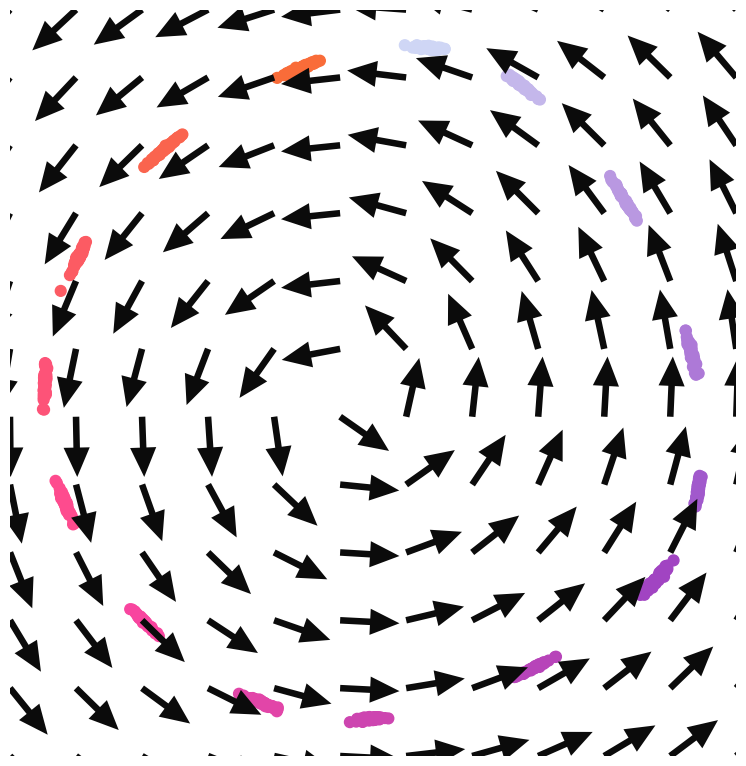

In [10]:
bounds = get_bounds(X_low, margin=0.05)
grid_points = get_grid_pts(bounds, n_pts=12)  # few and bold arrows, the figure is printed under one inch wide
width = (bounds[1] - bounds[0]).item()
spacing = width / 11

V_grid = model(grid_points).detach()
V_grid_unit = V_grid / (V_grid.norm(dim=1, keepdim=True) + 1e-12)

plt.figure(figsize=(8, 8))
plt.scatter(X_low[:, 0], X_low[:, 1], c=community_labels, cmap=cmap, s=60)
plt.quiver(
    grid_points[:, 0],
    grid_points[:, 1],
    V_grid_unit[:, 0],
    V_grid_unit[:, 1],
    color=INK,
    scale=1 / (0.9 * spacing),  # arrow length: 90% of the spacing of the grid
    width=0.009, headwidth=4, headlength=4.5,
    angles="xy",
    scale_units="xy",
)
plt.xlim(bounds[0], bounds[1])
plt.ylim(bounds[2], bounds[3])
plt.tight_layout()
plt.axis("off")
plt.savefig("disbm_vector_field.pdf", dpi=300, bbox_inches='tight',pad_inches=0.)
plt.show()
